### packages

In [1]:
#packages
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.colors as colors #for logarithmic color scales
import matplotlib.font_manager as fm #for importing my font
import matplotlib.ticker as ticker #for legend formatting
import matplotlib.patches as patches #for customizing matplot elements
from matplotlib.colors import ListedColormap #for easier color mapping
import seaborn as sns
import pyarrow
from pathlib import Path

In [2]:
#%pip freeze > requirements.txt

### figure formatting

#### custom colors for figures (to match my pres. theme)

In [3]:
#pres. theme colors
light_blue = "#d8ecf8"
blue = "#7eaecb"
light_navy = "#7c88d6"
navy = "#3d4578"
cranberry = "#be1e5c"
#neutrals:
cool_light_gray = "#eff3f4"
cool_gray = "#99a6b5"
offwhite = "#f7f8f9"

#create colormap
my_hex_colors = [navy, cranberry] #highest vals are cranberry
custom_cmap = colors.LinearSegmentedColormap.from_list("my_gradient", my_hex_colors) #GEMINI

#alternate colormap for variety
emerald = "#2b8977"
my_hex_colors_alt = [cranberry, "#cda457", emerald]
custom_cmap_alt = colors.LinearSegmentedColormap.from_list("my_gradient", my_hex_colors_alt)


#custom color dictionary for continents:
continent_colors = {
    'Africa': "#8E74B8", 
    'Asia': emerald, 
    'Europe': blue, 
    'North America': navy,
    'Oceania': "#F6A2D0",
    'South America': "#B02E62"
}

#### fonts (used Gemini)

In [4]:
font_file = Path("assets") / "DMSans[opsz,wght].ttf"

# Create individual configuration hooks for headers and scales
title_font = fm.FontProperties(fname=font_file,
                               size=16, weight = 'bold')
label_font = fm.FontProperties(fname=font_file,
                               size=12, weight = 'normal')
tick_font  = fm.FontProperties(fname=font_file,
                               size=9)

#### function to prevent scientific notation labeling (GEMINI)

In [5]:
def human_readable_format(x, pos):
    if x >= 1e9:
        return f'{x*1e-9:g}B'
    elif x >= 1e6:
        return f'{x*1e-6:g}M'
    elif x >= 1e3:
        return f'{x*1e-3:g}K'
    return f'{x:g}'

#### figure resolution settings (GEMINI)

In [6]:
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 300

### download and read data (Copilot)

In [7]:
import requests
import zipfile
from pathlib import Path

data_folder = Path("data/climactor_doi_download")
data_folder.mkdir(parents=True, exist_ok=True)

zip_path = data_folder.parent / "climactor_doi_download.zip"
download_url = "https://dataverse.unc.edu/api/access/dataset/:persistentId/?persistentId=doi:10.15139/S3/GGWVVQ"

if not zip_path.exists():
    temporary_zip_path = zip_path.with_suffix(".zip.part")
    try:
        with requests.get(download_url, stream=True, timeout=(30, 300)) as response:
            response.raise_for_status()
            with temporary_zip_path.open("wb") as zip_file:
                for chunk in response.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        zip_file.write(chunk)
        temporary_zip_path.replace(zip_path)
    finally:
        if temporary_zip_path.exists():
            temporary_zip_path.unlink()

with zipfile.ZipFile(zip_path) as archive:
    archive.extractall(data_folder)

climactor_1_keydict = pd.read_parquet(data_folder / "ClimActor_1_keydict.parquet")
climactor_2_actor = pd.read_csv(data_folder / "ClimActor_2_actor-1.csv")
climactor_3_emissions_agg = pd.read_csv(data_folder / "ClimActor_3_emissions_agg-1.csv")
climactor_4_emissions_sectors = pd.read_csv(data_folder / "ClimActor_4_emissions_sectors-1.csv")
climactor_5_targets = pd.read_csv(data_folder / "ClimActor_5_targets-1.csv")
climactor_6_plans = pd.read_csv(data_folder / "ClimActor_6_plans-1.csv")
climactor_7_initiatives = pd.read_csv(data_folder / "ClimActor_7_initiatives.csv")
ipcc_plan_type_climactor_enhanced = pd.read_csv(data_folder / "ipcc_plan_type_climactor_enhanced")

print("Loaded data shapes:")
print("ClimActor 1 key dictionary:", climactor_1_keydict.shape)
print("ClimActor 2 actors:", climactor_2_actor.shape)
print("ClimActor 3 aggregated emissions:", climactor_3_emissions_agg.shape)
print("ClimActor 4 emissions sectors:", climactor_4_emissions_sectors.shape)
print("ClimActor 5 targets:", climactor_5_targets.shape)
print("ClimActor 6 plans:", climactor_6_plans.shape)
print("ClimActor 7 initiatives:", climactor_7_initiatives.shape)
print("IPCC plan types:", ipcc_plan_type_climactor_enhanced.shape)

/tmp/ipykernel_1151/2364350729.py:31: DtypeWarning: Columns (4: scope, 7: ghgs_included) have mixed types. Specify dtype option on import or set low_memory=False.
  climactor_4_emissions_sectors = pd.read_csv(data_folder / "ClimActor_4_emissions_sectors-1.csv")


Loaded data shapes:
ClimActor 1 key dictionary: (1557003, 29)
ClimActor 2 actors: (44177, 6)
ClimActor 3 aggregated emissions: (25138, 18)
ClimActor 4 emissions sectors: (169689, 10)
ClimActor 5 targets: (20969, 17)
ClimActor 6 plans: (19562, 10)
ClimActor 7 initiatives: (11510, 8)
IPCC plan types: (8606, 19)


#### from the ClimActor paper:
(https://www.nature.com/articles/s41597-026-07288-y)

ClimActor v2.0 includes 7 main datasets: 

i) a key dictionary for subnational entities; -- for merging the other csvs

ii) an actor database that includes all entities identified in the selected databases;

iii) an emissions database that includes data on aggregated emissions for all sectors, GHGs, and scopes reported; 

iv) reported data on sector-specific emissions; 

v) climate action plans that include information about climate plan characteristics;

vi) climate target information, including descriptive information on an entity’s mitigation target; and 

vii) climate initiative participation of subnational entities and their focus

### create dfs with the variables I want

#### select columns from keydict + create new ones

In [9]:
#predefine columns I want from keydict
keydict = climactor_1_keydict[["entity_type",
                               "right_simpl", #name
                               "climactor_id", #key column
                               "iso", #country code
                               "long_lat", #coordinates
                               "area", #surface area
                               "population"]].drop_duplicates() #drop duplicate rows of keydict because there are multiple values of column "wrong"


#convert keydict's coordinates into separate columns for easier handling later (COPILOT)
coordinates = keydict["long_lat"].astype("string").str.extract(
    r"^\s*\[?\s*([-+]?\d+(?:\.\d+)?)\s*\]?\s*-\s*\[?\s*([-+]?\d+(?:\.\d+)?)\s*\]?\s*$"
)
keydict[["longitude", "latitude"]] = coordinates.apply(pd.to_numeric, errors="coerce")
keydict = keydict.drop(columns = "long_lat") #remove unformatted coordinate column

keydict = keydict.dropna(subset=['longitude', 'latitude']) #remove rows without coordinate values

##### use coordinates to categorize entities into continents (GEMINI)

In [10]:
from shapely.geometry import Point

# --- STEP 1: LOAD A WORLD MAP WITH CONTINENT BOUNDARIES ---
# Reading directly from an open-source natural earth repository to get continent names
world = gpd.read_file("data/world.geojson")
world = world[['continent', 'geometry']]

# --- STEP 2: CONVERT keydict TO A GEODATAFRAME ---
# Parse your long_lat values into explicit geometry Points. 
geometry = [Point(xy) for xy in zip(keydict['longitude'], keydict['latitude'])]
geokeydict_pre = gpd.GeoDataFrame(keydict, geometry=geometry, crs="EPSG:4326")

# --- STEP 3: SPATIAL JOIN TO ADD CONTINENT COLUMN ---
# This looks at which continent polygon each point sits inside
geokeydict = gpd.sjoin(geokeydict_pre, world, how="left", predicate="within")

#### merge dfs (maintaining geospatial features)

##### emissions

In [11]:
emissions = geokeydict.merge(
    climactor_3_emissions_agg[["climactor_id", "inv_year", "total_emissions", "inv_unit"]], 
    on = "climactor_id",
    how = "right")
#add emissions per capita variable (that I didn't end up using)
emissions["total_emissions_per_cap"] = emissions["total_emissions"] / emissions["population"]

#remove the random Belgian city whose emissions are 100x the second highest emitting city
#because it's probably an error, though I'd want to verify with DDL
emissions = emissions[emissions["climactor_id"] != "a684195e0492457c"]
#remove Belpasso, Italy which has an inv_year of 2030, but the rest are 2023 are sooner
emissions = emissions[emissions["inv_year"] <= 2026]

#only keep the most recent year for each location for simpler visualizations (GEMINI)
# 1. Sort by year ascending so the most recent year is at the bottom
# 2. Keep only the last occurrence (the most recent year) for each location
emissions_asynch = emissions.sort_values(by = 'inv_year').drop_duplicates(subset=['climactor_id'], keep='last').copy()

view rows with missing values:

In [12]:
emissions_asynch[emissions_asynch.isna().any(axis=1)]

#the missing values in continent could be due to errors in the coordinate borders in world.geojson, but I don't have time to debug that

,entity_type,right_simpl,climactor_id,iso,area,population,longitude,latitude,geometry,index_right,continent,inv_year,total_emissions,inv_unit,total_emissions_per_cap
12402,City,Palermo,111c2a8a010dc53d,ITA,160.226416,648980.0,13.331049,38.130253,POINT (13.33105 38.13025),NaN,NaN,1990,1875375.10,tCO2,2.889727
18350,Region,Illes Balears,fbef904f6a6ce638,ESP,4990.791438,1188780.0,2.91243,39.574052,POINT (2.91243 39.57405),NaN,NaN,1990,6081000.00,tCO2e,5.115328
18487,City,Andora,a6ccf6b35f2c710c,ITA,31.843505,7023.0,8.124541,43.981196,POINT (8.12454 43.9812),NaN,NaN,2004,39093.20,tCO2,5.566453
18376,City,Cadaques,7add38785d1024fb,ESP,26.603993,2733.0,3.273661,42.290799,POINT (3.27366 42.2908),NaN,NaN,2005,36607609.17,tCO2e,13394.661240
16842,SubRegion,Had-Dingli,a0d4b458784715cd,MLT,7.140999,3551.0,14.381829,35.859929,POINT (14.38183 35.85993),NaN,NaN,2005,9261.70,tCO2,2.608195
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
18169,SubRegion,Tanjung Pinang,c11bec2f14b56899,IDN,150.384547,147402.0,104.487064,0.919581,POINT (104.48706 0.91958),NaN,NaN,2021,206.62,tCO2e,0.001402
6875,City,Valldemossa,20191d31ee9b2877,ESP,42.886008,2067.0,2.619984,39.703891,POINT (2.61998 39.70389),NaN,NaN,2021,11224.00,tCO2e,5.430092
1003,SubRegion,Middelfart,bc405d4863508501,DNK,528.585375,39510.0,9.885606,55.452218,POINT (9.88561 55.45222),NaN,NaN,2021,351275.00,tCO2e,8.890787
1040,SubRegion,Arendal,9f6ef1ac196fec96,NOR,545.189584,44587.0,8.765241,58.491842,POINT (8.76524 58.49184),NaN,NaN,2021,97354.00,tCO2e,2.183462


##### bias in `inv_unit` (before and after filtering outdated years)

In [13]:
pd.crosstab(emissions['continent'], emissions['inv_unit'])

inv_unit,tCO2,tCO2e
continent,,
Africa,0,51
Asia,315,269
Europe,9952,12469
North America,0,638
Oceania,0,88
South America,0,314


In [14]:
pd.crosstab(emissions_asynch['continent'], emissions_asynch['inv_unit'])

inv_unit,tCO2,tCO2e
continent,,
Africa,0,19
Asia,285,126
Europe,2542,3901
North America,0,242
Oceania,0,26
South America,0,132


##### climate plans

In [15]:
#merge plans on geographic keydict 
plans = geokeydict.merge(
    climactor_6_plans[["climactor_id", "plan_type"]], 
    on = "climactor_id",
    how = "left")


#simplify plan_type categories for visualization (partly GEMINI)
new_categories = {
    "": "No Reported Plan", #replacing missing plans with a real value
    np.nan: "No Reported Plan",
    "Integrated": "Integrated / Joint",
    "Joint": "Integrated / Joint",
    "Energy": "Energy / Access",
    "Access to Energy": "Energy / Access",
    "Action": "Other"
}
plans["plan_type"] = plans["plan_type"].replace(new_categories)

plans["plan_type"].unique() #print new column values

<ArrowStringArray>
[  'No Reported Plan',         'Mitigation',         'Adaptation',
 'Integrated / Joint',    'Energy / Access',              'Other']
Length: 6, dtype: str

In [16]:
#for viewing geodataframes with DataWrangler extension (GEMINI)
emissions_view = emissions.drop(columns='geometry')
emissions_asynch_view = emissions_asynch.drop(columns='geometry')
plans_view = plans.drop(columns='geometry')

### exploratory scatterplot

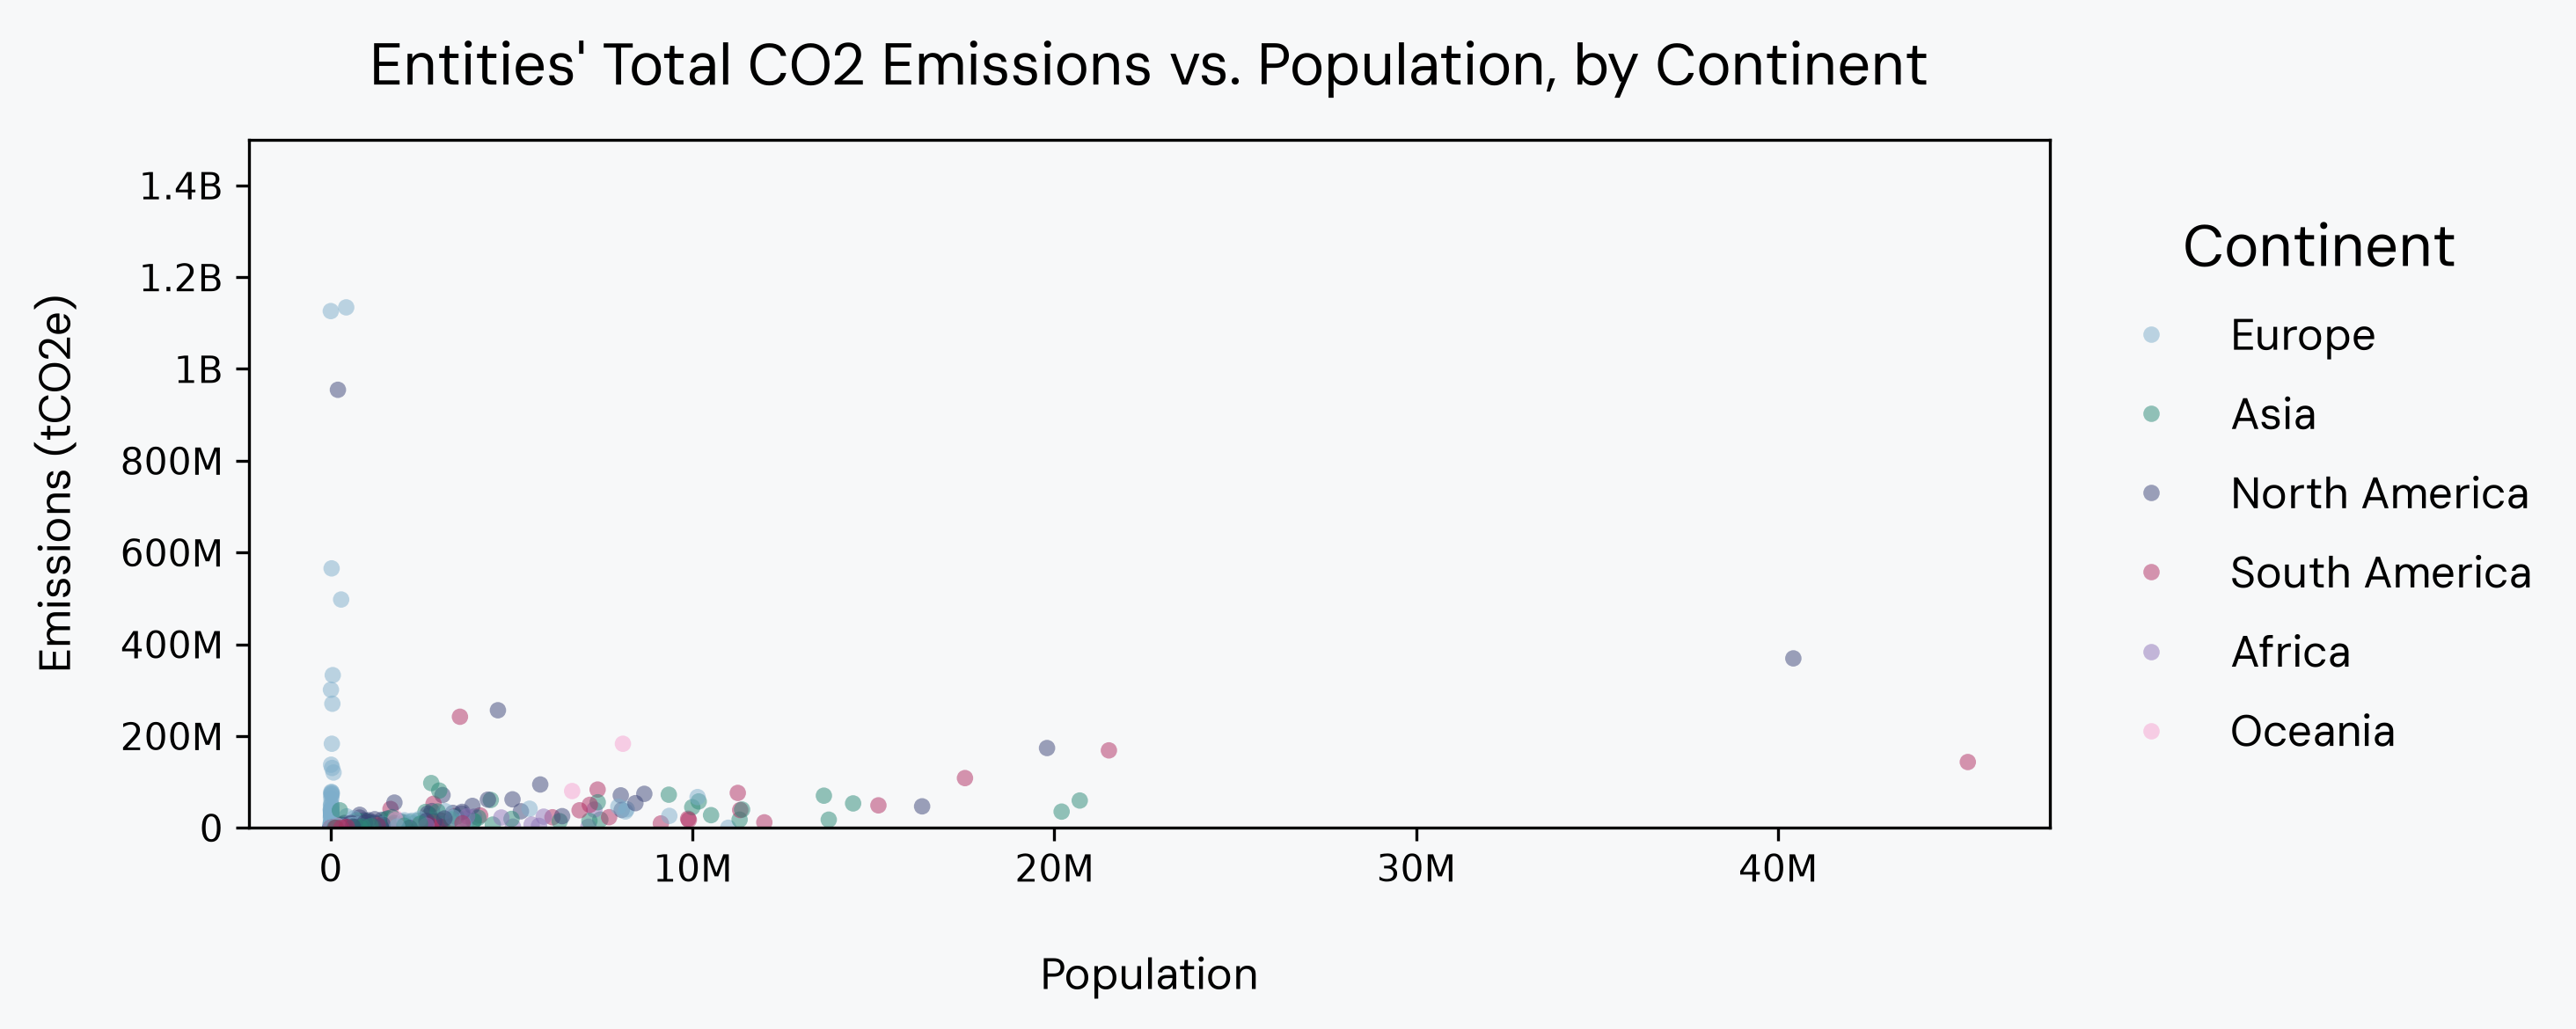

In [17]:
#filter for only entities that measured by tCO2e
emissions_tco2e = emissions_asynch[emissions_asynch["inv_unit"] == "tCO2e"].copy()


fig, ax = plt.subplots(figsize=(10, 4))
fig.patch.set_facecolor(offwhite) #bg color

# Use the 'hue' parameter to automatically group and color-code by continent
sns.scatterplot(
    data = emissions_tco2e, 
    x = "population",
    y = "total_emissions",
    hue = 'continent',
    palette = continent_colors,
    alpha = 0.5,
    edgecolor='none',  
    s=20,                        # Adjusts marker size
    ax=ax
).set_facecolor(offwhite) #plot bg color

ax.set_title("Entities' Total CO2 Emissions vs. Population, by Continent", pad = 15, fontproperties=title_font)
ax.set_ylim(0, 1500000000)

#remove scientific notation from axis labels
ax.yaxis.set_major_formatter(ticker.FuncFormatter(human_readable_format))
ax.xaxis.set_major_formatter(ticker.FuncFormatter(human_readable_format))

plt.xlabel("Population",
           fontproperties = label_font, 
           labelpad = 15)
plt.ylabel("Emissions (tCO2e)", 
           fontproperties = label_font, 
           labelpad = 10)
plt.legend(title="Continent",
           prop = label_font, #label font
           title_fontproperties = title_font, #legend title font
           frameon = False,
           loc='center', #anchor point
           bbox_to_anchor=(1.15, 0.5)) #coordinates
plt.tight_layout()

plt.savefig("figures/emissions_v_population.png", bbox_inches='tight')
plt.show()

#### identify potential anomalies seen above

In [18]:
display(emissions_asynch[(emissions_asynch["population"] < 1000000) & 
                         (emissions_asynch["total_emissions"] > 200000000)])

,entity_type,right_simpl,climactor_id,iso,area,population,longitude,latitude,geometry,index_right,continent,inv_year,total_emissions,inv_unit,total_emissions_per_cap
1351,City,Greifswald,aa29264f881eac56,DEU,87.388405,54831.0,13.414008,54.089422,POINT (13.41401 54.08942),41.0,Europe,2003,3.327186e+08,tCO2e,6.068074e+03
18373,City,Beneixida,4c1a3b6544a90e15,ESP,3.196172,658.0,-0.548764,39.070518,POINT (-0.54876 39.07052),49.0,Europe,2010,1.126106e+09,tCO2e,1.711407e+06
18371,SubRegion,Azambuja,2ef373037a36a7a5,PRT,339.037874,23093.0,-8.896872,39.133668,POINT (-8.89687 39.13367),130.0,Europe,2015,5.653571e+08,tCO2e,2.448175e+04
18370,City,Arona,4ac270302a875b6d,ESP,81.598502,73624.0,-16.67604,28.055262,POINT (-16.67604 28.05526),NaN,NaN,2018,2.515864e+08,tCO2e,3.417179e+03
1347,City,Deinze,23254a96f2199c83,BEL,195.418952,43965.0,3.534903,51.019605,POINT (3.5349 51.0196),12.0,Europe,2019,2.703793e+08,tCO2e,6.149875e+03
1370,City,Poltava,e60dcd122b5f02d9,UKR,104.225081,287013.0,34.544582,49.601909,POINT (34.54458 49.60191),166.0,Europe,2020,4.975190e+08,tCO2e,1.733437e+03
1388,City,Viciebsk,6c293857933a90e4,BLR,134.734486,426640.0,30.205714,55.197593,POINT (30.20571 55.19759),19.0,Europe,2020,1.134191e+09,tCO2e,2.658425e+03
18222,SubRegion,Ciudad Madero,ee5414e38ddc7001,MEX,50.102245,197309.0,-97.829243,22.280361,POINT (-97.82924 22.28036),102.0,North America,2021,9.545640e+08,tCO2e,4.837914e+03
1355,City,Jablonna Lacka,49d8275bf166b674,POL,244.724765,4698.0,22.45041,52.484631,POINT (22.45041 52.48463),127.0,Europe,2022,3.008558e+08,tCO2e,6.403913e+04


### U.S. cities in the dataset



In [19]:
emissions_USA = emissions_asynch[(emissions_asynch["iso"] == "USA") & 
                                 (emissions_asynch["entity_type"] == "City")].copy()

#subsetting only cities to avoid redundant data (e.g., California and Los Angeles are separate rows)

In [20]:
display(emissions_USA)

,entity_type,right_simpl,climactor_id,iso,area,population,longitude,latitude,geometry,index_right,continent,inv_year,total_emissions,inv_unit,total_emissions_per_cap
17887,City,Wilmington,1ac99e7036bcf97e,USA,135.126307,116113.0,-77.887262,34.210437,POINT (-77.88726 34.21044),168.0,North America,2007,9704.00,tCO2e,0.083574
17856,City,Greensboro,08049f066e8f7b64,USA,361.364717,315053.0,-79.824196,36.094722,POINT (-79.8242 36.09472),168.0,North America,2007,117708.00,tCO2e,0.373613
17929,City,Reno,bfbffac608860592,USA,289.618986,245169.0,-119.84807,39.549448,POINT (-119.84807 39.54945),168.0,North America,2008,2751878.90,tCO2e,11.224416
889,City,Grand Rapids,0d2605ba1e81983c,USA,118.186716,199794.0,-85.656193,42.961936,POINT (-85.65619 42.96194),168.0,North America,2009,1295285.00,tCO2e,6.483103
18271,City,Tumwater,c941be1047c46a32,USA,46.653337,24656.0,-122.917687,46.98926,POINT (-122.91769 46.98926),168.0,North America,2015,2865220.00,tCO2e,116.207820
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
802,City,Columbus,31724eab4921425d,USA,588.937717,942418.0,-82.985325,39.985938,POINT (-82.98532 39.98594),168.0,North America,2022,11224184.53,tCO2e,11.909985
734,City,Salt Lake City,d0fb8cc1194800c8,USA,288.368720,217859.0,-111.9305,40.777204,POINT (-111.9305 40.7772),168.0,North America,2022,4428904.64,tCO2e,20.329225
1163,City,Davie,e06a5e0bba284cde,USA,92.634941,102316.0,-80.28697,26.07894,POINT (-80.28697 26.07894),168.0,North America,2022,981560.82,tCO2e,9.593424
17751,City,Tampa,9f22dc7146bb6f93,USA,312.121875,397541.0,-82.445062,27.996205,POINT (-82.44506 27.99621),168.0,North America,2022,98000.00,tCO2e,0.246515


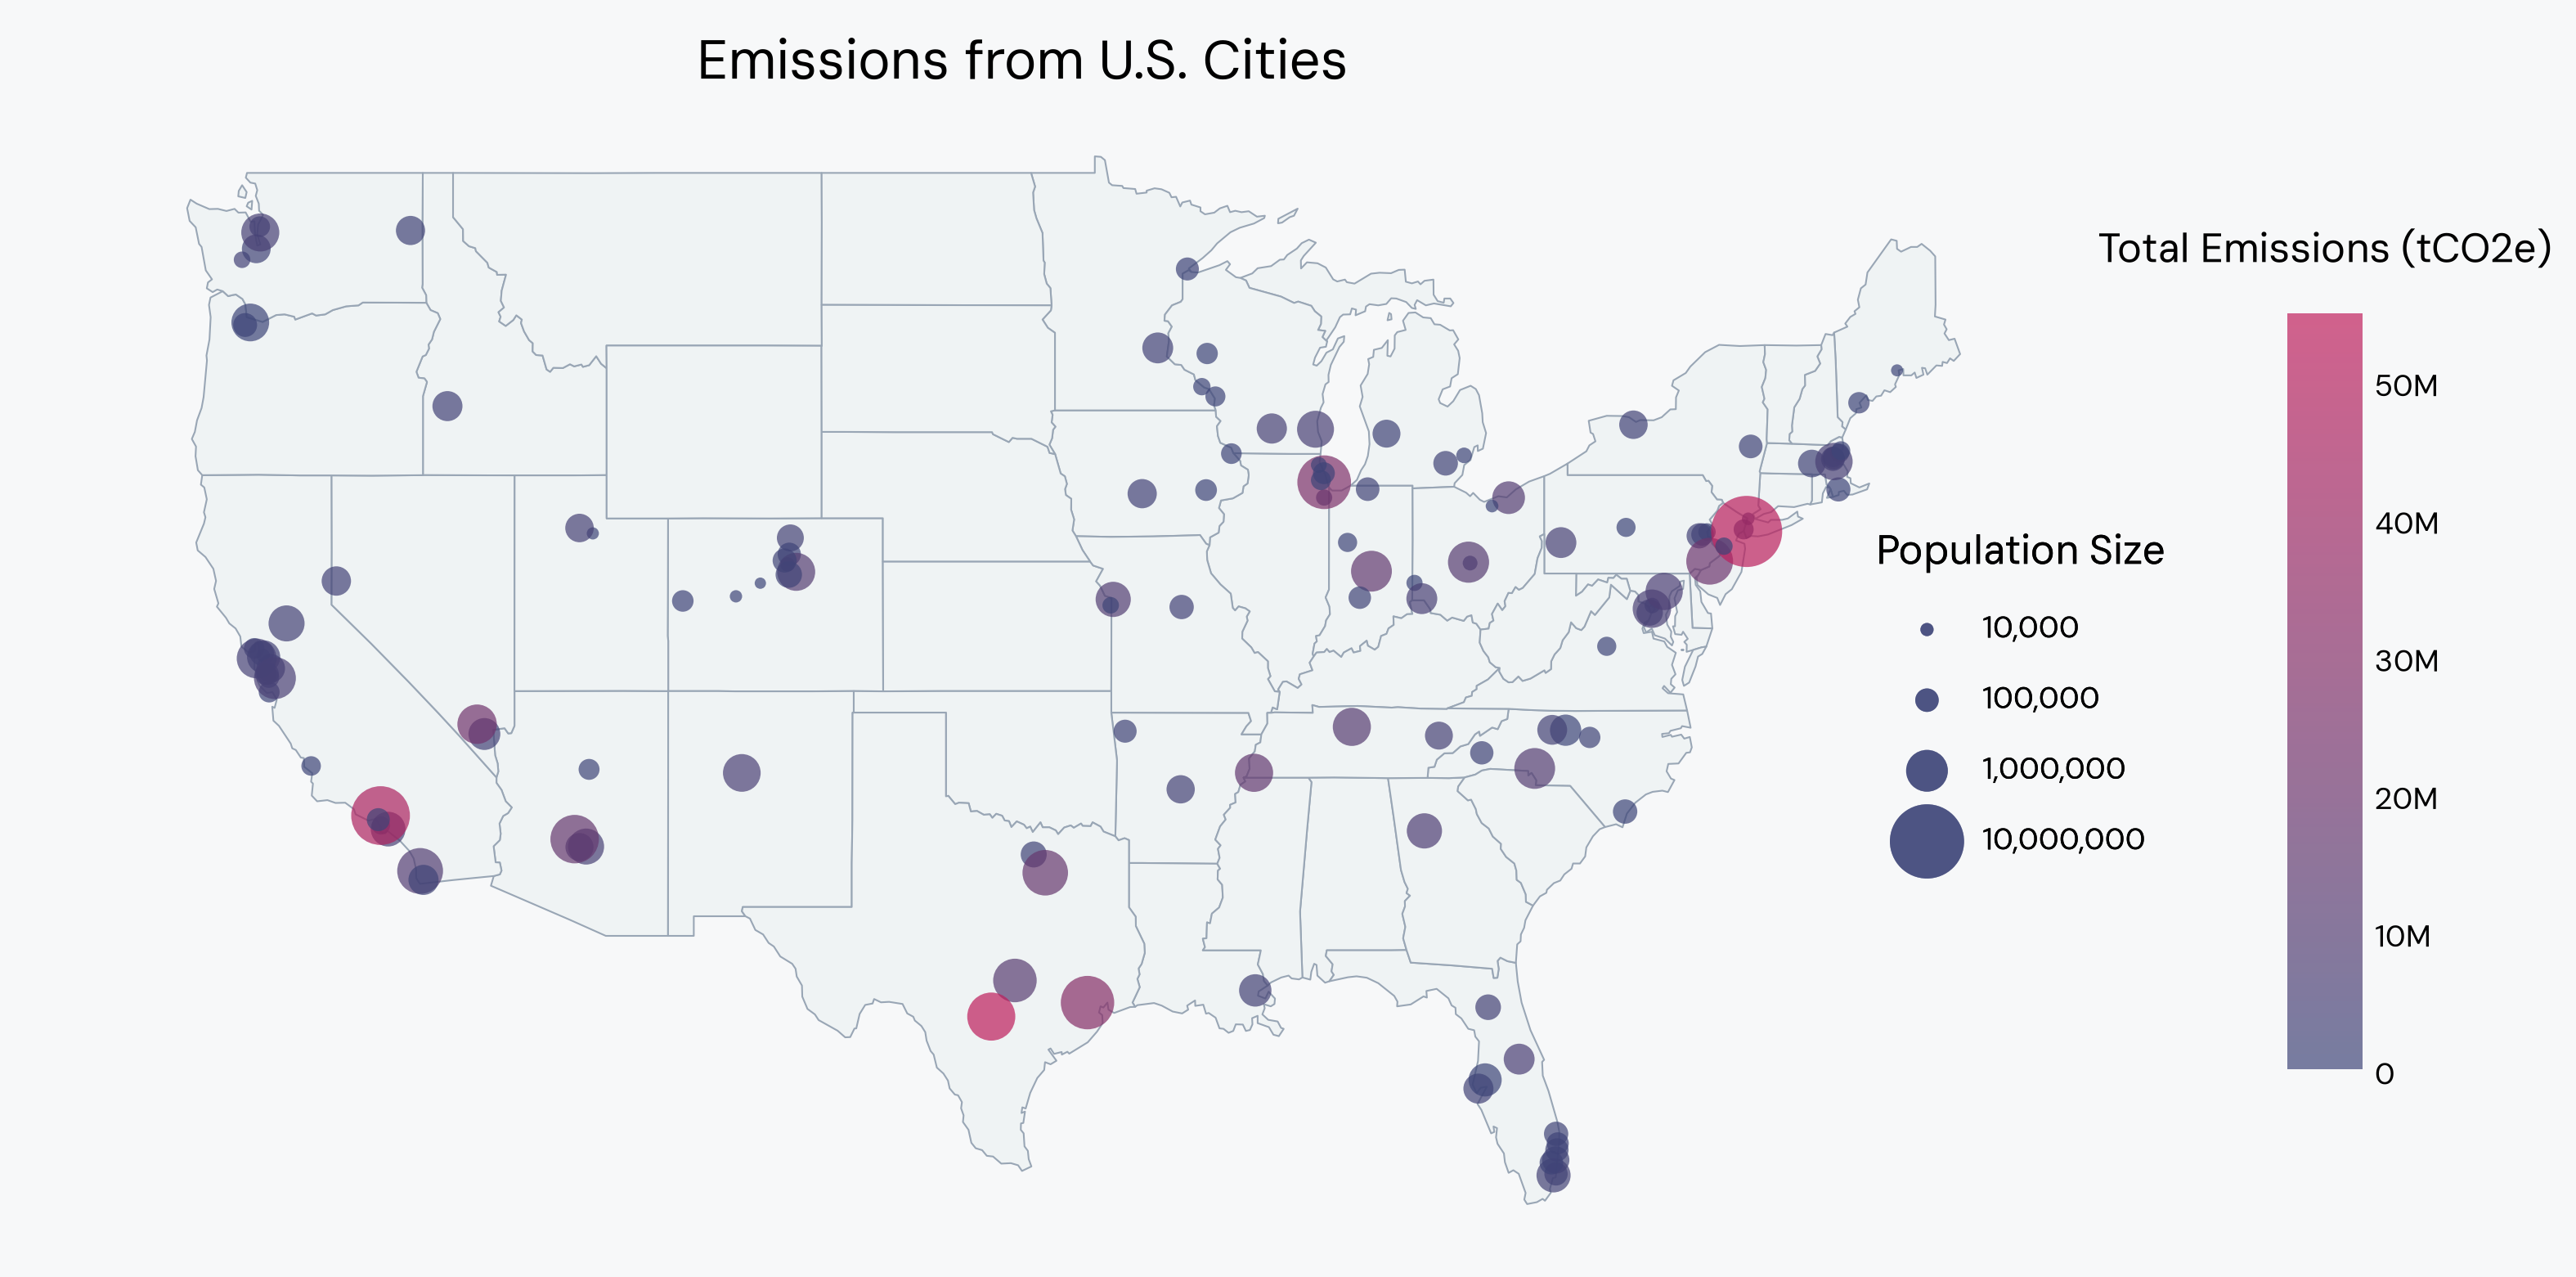

In [21]:
fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor(offwhite) #bg color
point_opacity = 0.7
point_scale = 0.15

#use a defined map of the US (GEMINI)
usa = gpd.read_file("data/usa.geojson")
usa.plot(ax=ax,
         color = cool_light_gray, #fill
         edgecolor = cool_gray,
         linewidth = 0.5)


# Layer scatter points using the merged US GeoDataFrame (partly GEMINI)
sc = ax.scatter(
    data = emissions_USA,
    x = 'longitude',
    y = 'latitude',
    c = 'total_emissions', 
    cmap = custom_cmap,
    #norm=colors.LogNorm(),   # <-- AUTOMATICALLY SCALES COLORS LOGARITHMICALLY
    s = np.sqrt(emissions_USA['population']) * point_scale, #size of points is mapped to population size (regularized)
    alpha = point_opacity,
    edgecolor='none'        # Optional: removes white borders from points for a cleaner look
)


#legend: color scale for emissions (GEMINI)
cbar = fig.colorbar(sc, ax=ax, orientation='vertical',
                    shrink=0.5,
                    pad=0.1,
                    aspect = 10)
cbar.ax.set_title('Total Emissions (tCO2e)', pad = 15, fontproperties=label_font) #legend title
cbar.outline.set_visible(False) #remove bar outline
cbar.ax.tick_params(size=0) #remove bar ticks
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(human_readable_format)) #remove scientific notation

for label in cbar.ax.get_yticklabels(): #font of colorbar tick labels
    label.set_fontproperties(tick_font)

#legend: size scale for pop size (GEMINI)
handles, labels = [], []
for sample_pop in [10_000, 100_000, 1_000_000, 10_000_000]:
    sample_size = np.sqrt(sample_pop) * point_scale  # Must match the math in og regularizing function
    handles.append(plt.scatter([], [], s=sample_size,
                               color=navy, alpha=point_opacity, edgecolor='none'))
    labels.append(f"{sample_pop:,}")

size_legend = ax.legend(
    handles, labels, 
    title="Population Size", 
    loc='center', #anchor point
    bbox_to_anchor=(1.0, 0.5), #coordinates
    edgecolor = 'none',
    facecolor = 'none',
    labelspacing=1, 
    borderpad=0.8, 
    frameon=True,
    prop=tick_font, #number font
    title_fontproperties = label_font #legend title font
)
ax.add_artist(size_legend) # Prevents the size legend from resetting the canvas context


#formatting
ax.set_title("Emissions from U.S. Cities", fontproperties=title_font, pad=15)

# Clean up map constraints to focus nicely on the continental US
ax.set_xlim(-130, -65)
ax.set_ylim(24, 50)
ax.axis('off') #hides lat/long lines

plt.savefig("figures/us_cities_emissions.png", bbox_inches='tight')
plt.show()

Note: These data are asynchronous (the tCO2e measures are from potentially different years for each city)

### global data

#### global emissions

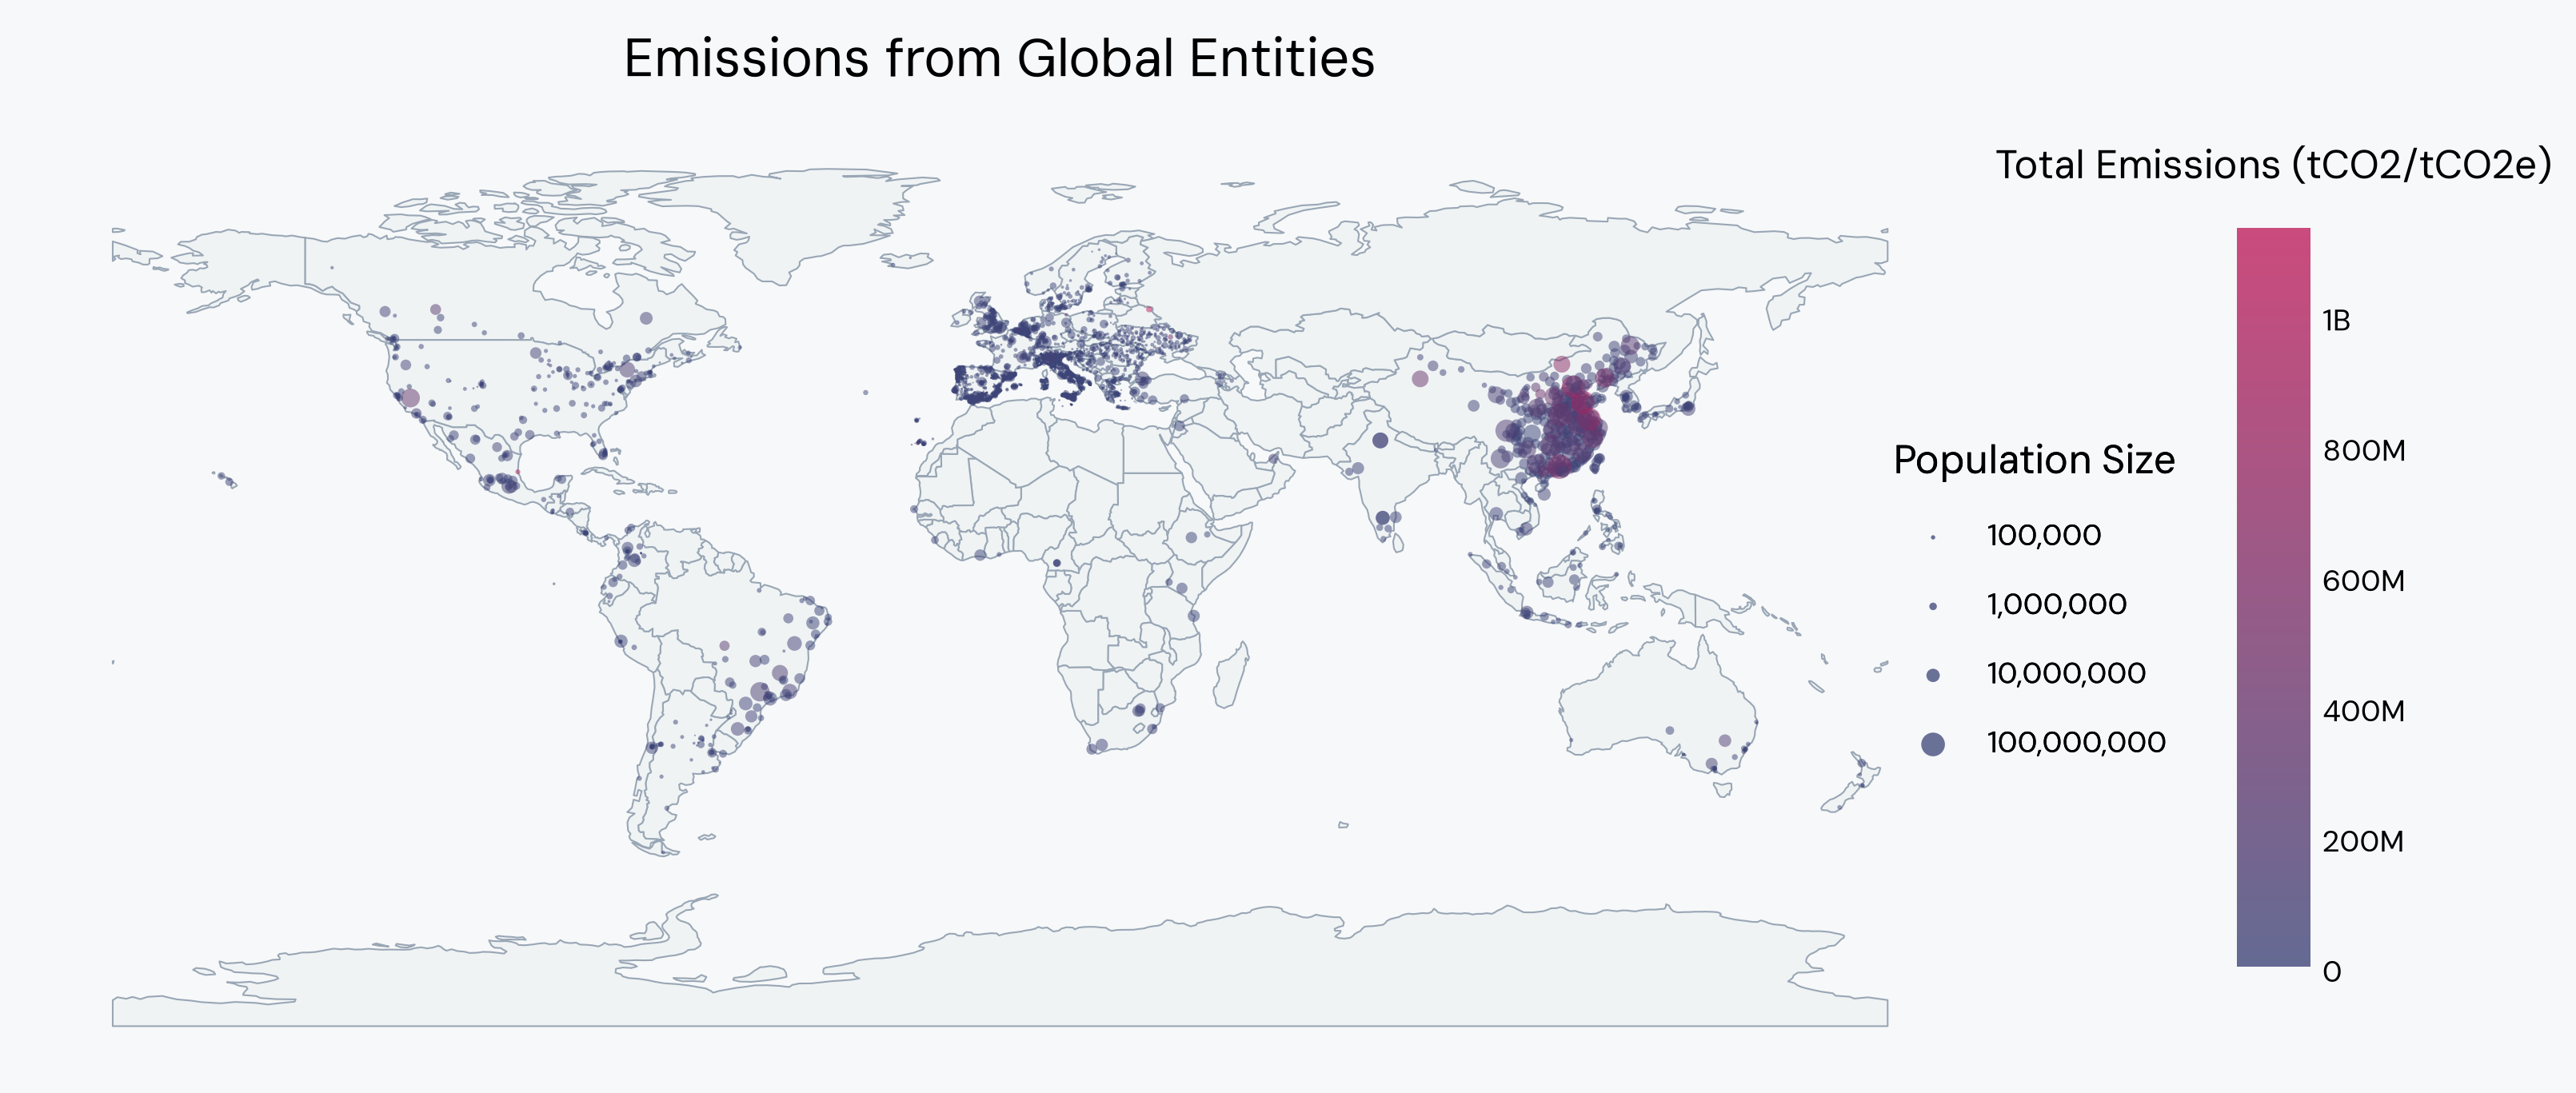

In [22]:
fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor(offwhite) #bg color
point_opacity = 0.5
point_scale = 0.005

#re-initialize world geojson to plot a world map this time
world = gpd.read_file("data/world.geojson")
world.plot(ax=ax,
         color = cool_light_gray, #fill
         edgecolor = cool_gray,
         linewidth = 0.5)


# Layer scatter points using the merged US GeoDataFrame (partly GEMINI)
sc = ax.scatter(
    data = emissions_asynch,
    x = 'longitude',
    y = 'latitude',
    c = 'total_emissions', 
    cmap = custom_cmap,
    #norm=colors.LogNorm(),   # <-- AUTOMATICALLY SCALES COLORS LOGARITHMICALLY
    s = np.sqrt(emissions_asynch['population']) * point_scale, #size of points is mapped to population size (regularized)
    alpha = point_opacity,
    edgecolor='none'        # Optional: removes white borders from points for a cleaner look
)


#legend: color scale for emissions (GEMINI)
cbar = fig.colorbar(sc, ax=ax, orientation='vertical',
                    shrink=0.5,
                    pad=0.1,
                    aspect = 10)
cbar.ax.set_title('Total Emissions (tCO2/tCO2e)', pad = 15, fontproperties=label_font) #legend title
cbar.outline.set_visible(False) #remove bar outline
cbar.ax.tick_params(size=0) #remove bar ticks
cbar.solids.set_alpha(0.8) #make more opaque than points
cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(human_readable_format)) #remove scientific notation

for label in cbar.ax.get_yticklabels(): #font of colorbar tick labels
    label.set_fontproperties(tick_font)

#legend: size scale for pop size (GEMINI)
handles, labels = [], []
for sample_pop in [100_000, 1_000_000, 10_000_000, 100_000_000]:
    sample_size = np.sqrt(sample_pop) * point_scale  # Must match the math in og regularizing function
    handles.append(plt.scatter([], [], s=sample_size,
                               color=navy, alpha=point_opacity, edgecolor='none'))
    labels.append(f"{sample_pop:,}")

size_legend = ax.legend(
    handles, labels, 
    title="Population Size", 
    loc='center', #anchor point
    bbox_to_anchor=(1.03, 0.5), #coordinates
    edgecolor = 'none',
    facecolor = 'none',
    labelspacing=1, 
    borderpad=0.8, 
    frameon=True,
    prop=tick_font, #number font
    title_fontproperties = label_font #legend title font
)
ax.add_artist(size_legend) # Prevents the size legend from resetting the canvas context


#formatting
ax.set_title("Emissions from Global Entities", fontproperties=title_font, pad=15)

#ax.set_xlim(-130, -65)
#ax.set_ylim(24, 50)
ax.axis('off') #hides lat/long lines

plt.savefig("figures/global_emissions.png", bbox_inches='tight')
plt.show()

#### global plot of most recent year with emissions data

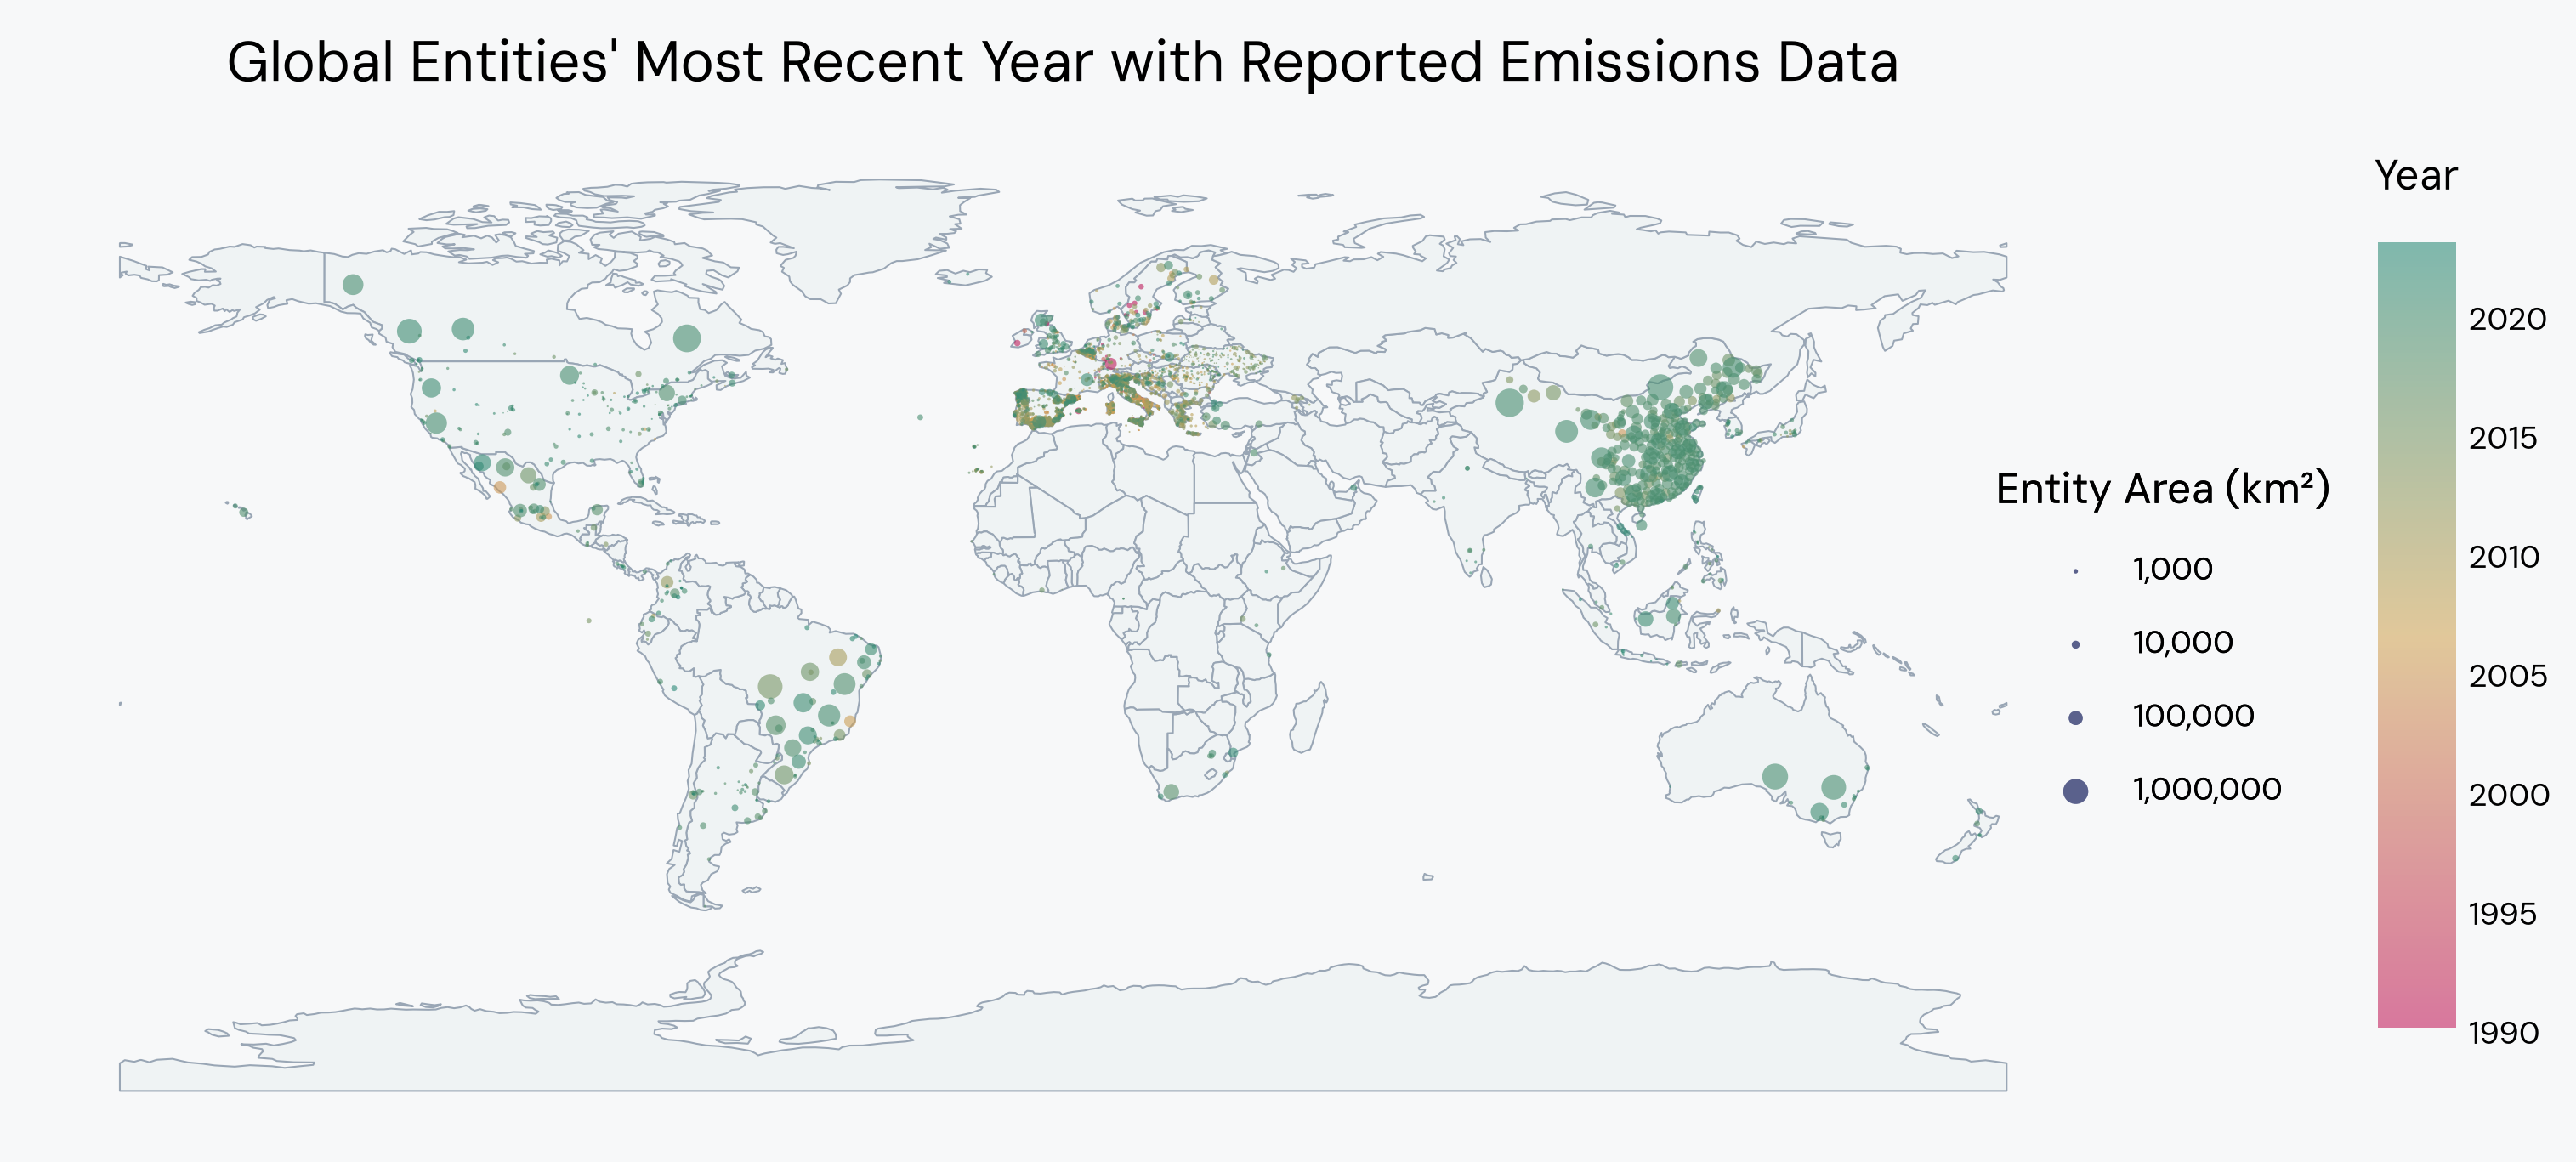

In [23]:
fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor(offwhite) #bg color
point_opacity = 0.6
point_scale = 0.05

#re-initialize world geojson to plot a world map this time
world = gpd.read_file("data/world.geojson")
world.plot(ax=ax,
         color = cool_light_gray, #fill
         edgecolor = cool_gray,
         linewidth = 0.5)


# Layer scatter points using the merged US GeoDataFrame (partly GEMINI)
sc = ax.scatter(
    data = emissions_asynch,
    x = 'longitude',
    y = 'latitude',
    c = 'inv_year', 
    cmap = custom_cmap_alt,
    vmax = 2023, #force the color scale to cut off at 2023 
    s = np.sqrt(emissions_asynch['area']) * point_scale, #size of points is mapped to area (regularized)
    alpha = point_opacity,
    edgecolor='none'        # Optional: removes white borders from points for a cleaner look
)


#legend: color scale for emissions (GEMINI)
cbar = fig.colorbar(sc, ax=ax, orientation='vertical',
                    shrink=0.5,
                    pad=0.1,
                    aspect = 10)
cbar.ax.set_title('Year', pad = 15, fontproperties=label_font) #legend title
cbar.outline.set_visible(False) #remove bar outline
cbar.ax.tick_params(size=0) #remove bar ticks
#cbar.ax.yaxis.set_major_formatter(ticker.FuncFormatter(human_readable_format)) #remove scientific notation

for label in cbar.ax.get_yticklabels(): #font of colorbar tick labels
    label.set_fontproperties(tick_font)

#legend: size scale for pop size (GEMINI)
handles, labels = [], []
for sample_area in [1_000, 10_000, 100_000, 1_000_000]:
    sample_size = np.sqrt(sample_area) * point_scale  # Must match the math in og regularizing function
    handles.append(plt.scatter([], [], s=sample_size,
                               color=navy, alpha=point_opacity, edgecolor='none'))
    labels.append(f"{sample_area:,}")

size_legend = ax.legend(
    handles, labels, 
    title="Entity Area (km²)", 
    loc='center', #anchor point
    bbox_to_anchor=(1.03, 0.5), #coordinates
    edgecolor = 'none',
    facecolor = 'none',
    labelspacing=1, 
    borderpad=0.8, 
    frameon=True,
    prop=tick_font, #number font
    title_fontproperties = label_font #legend title font
)
ax.add_artist(size_legend) # Prevents the size legend from resetting the canvas context


#formatting
ax.set_title("Global Entities' Most Recent Year with Reported Emissions Data", fontproperties=title_font, pad=15)

#ax.set_xlim(-130, -65)
#ax.set_ylim(24, 50)
ax.axis('off') #hides lat/long lines

plt.savefig("figures/global_emissions_recency_map.png", bbox_inches='tight')
plt.show()

(for choosing a variable to be represented by point size: area has probably been the same since 1990 whereas population may not be representative)

##### find entities who haven't updated since the 1990s

In [24]:
outdated_entities = emissions_asynch[emissions_asynch["inv_year"] < 2000].copy()

print(len(outdated_entities))
outdated_entities[["inv_year", "right_simpl", "entity_type"]].head(10)

47


,inv_year,right_simpl,entity_type
6147,1990,Guglionesi,City
20477,1990,San Giacomo Degli Schiavoni,City
20225,1990,Busso,City
1652,1990,Erlangen,SubRegion
1642,1990,Landau in der Pfalz,SubRegion
20232,1990,Termoli,City
17369,1990,Hagfors,SubRegion
21440,1990,Rofrano,City
17335,1990,Skovde,SubRegion
17336,1990,Ostersund,SubRegion


##### histogram representation (partly from Gemini)

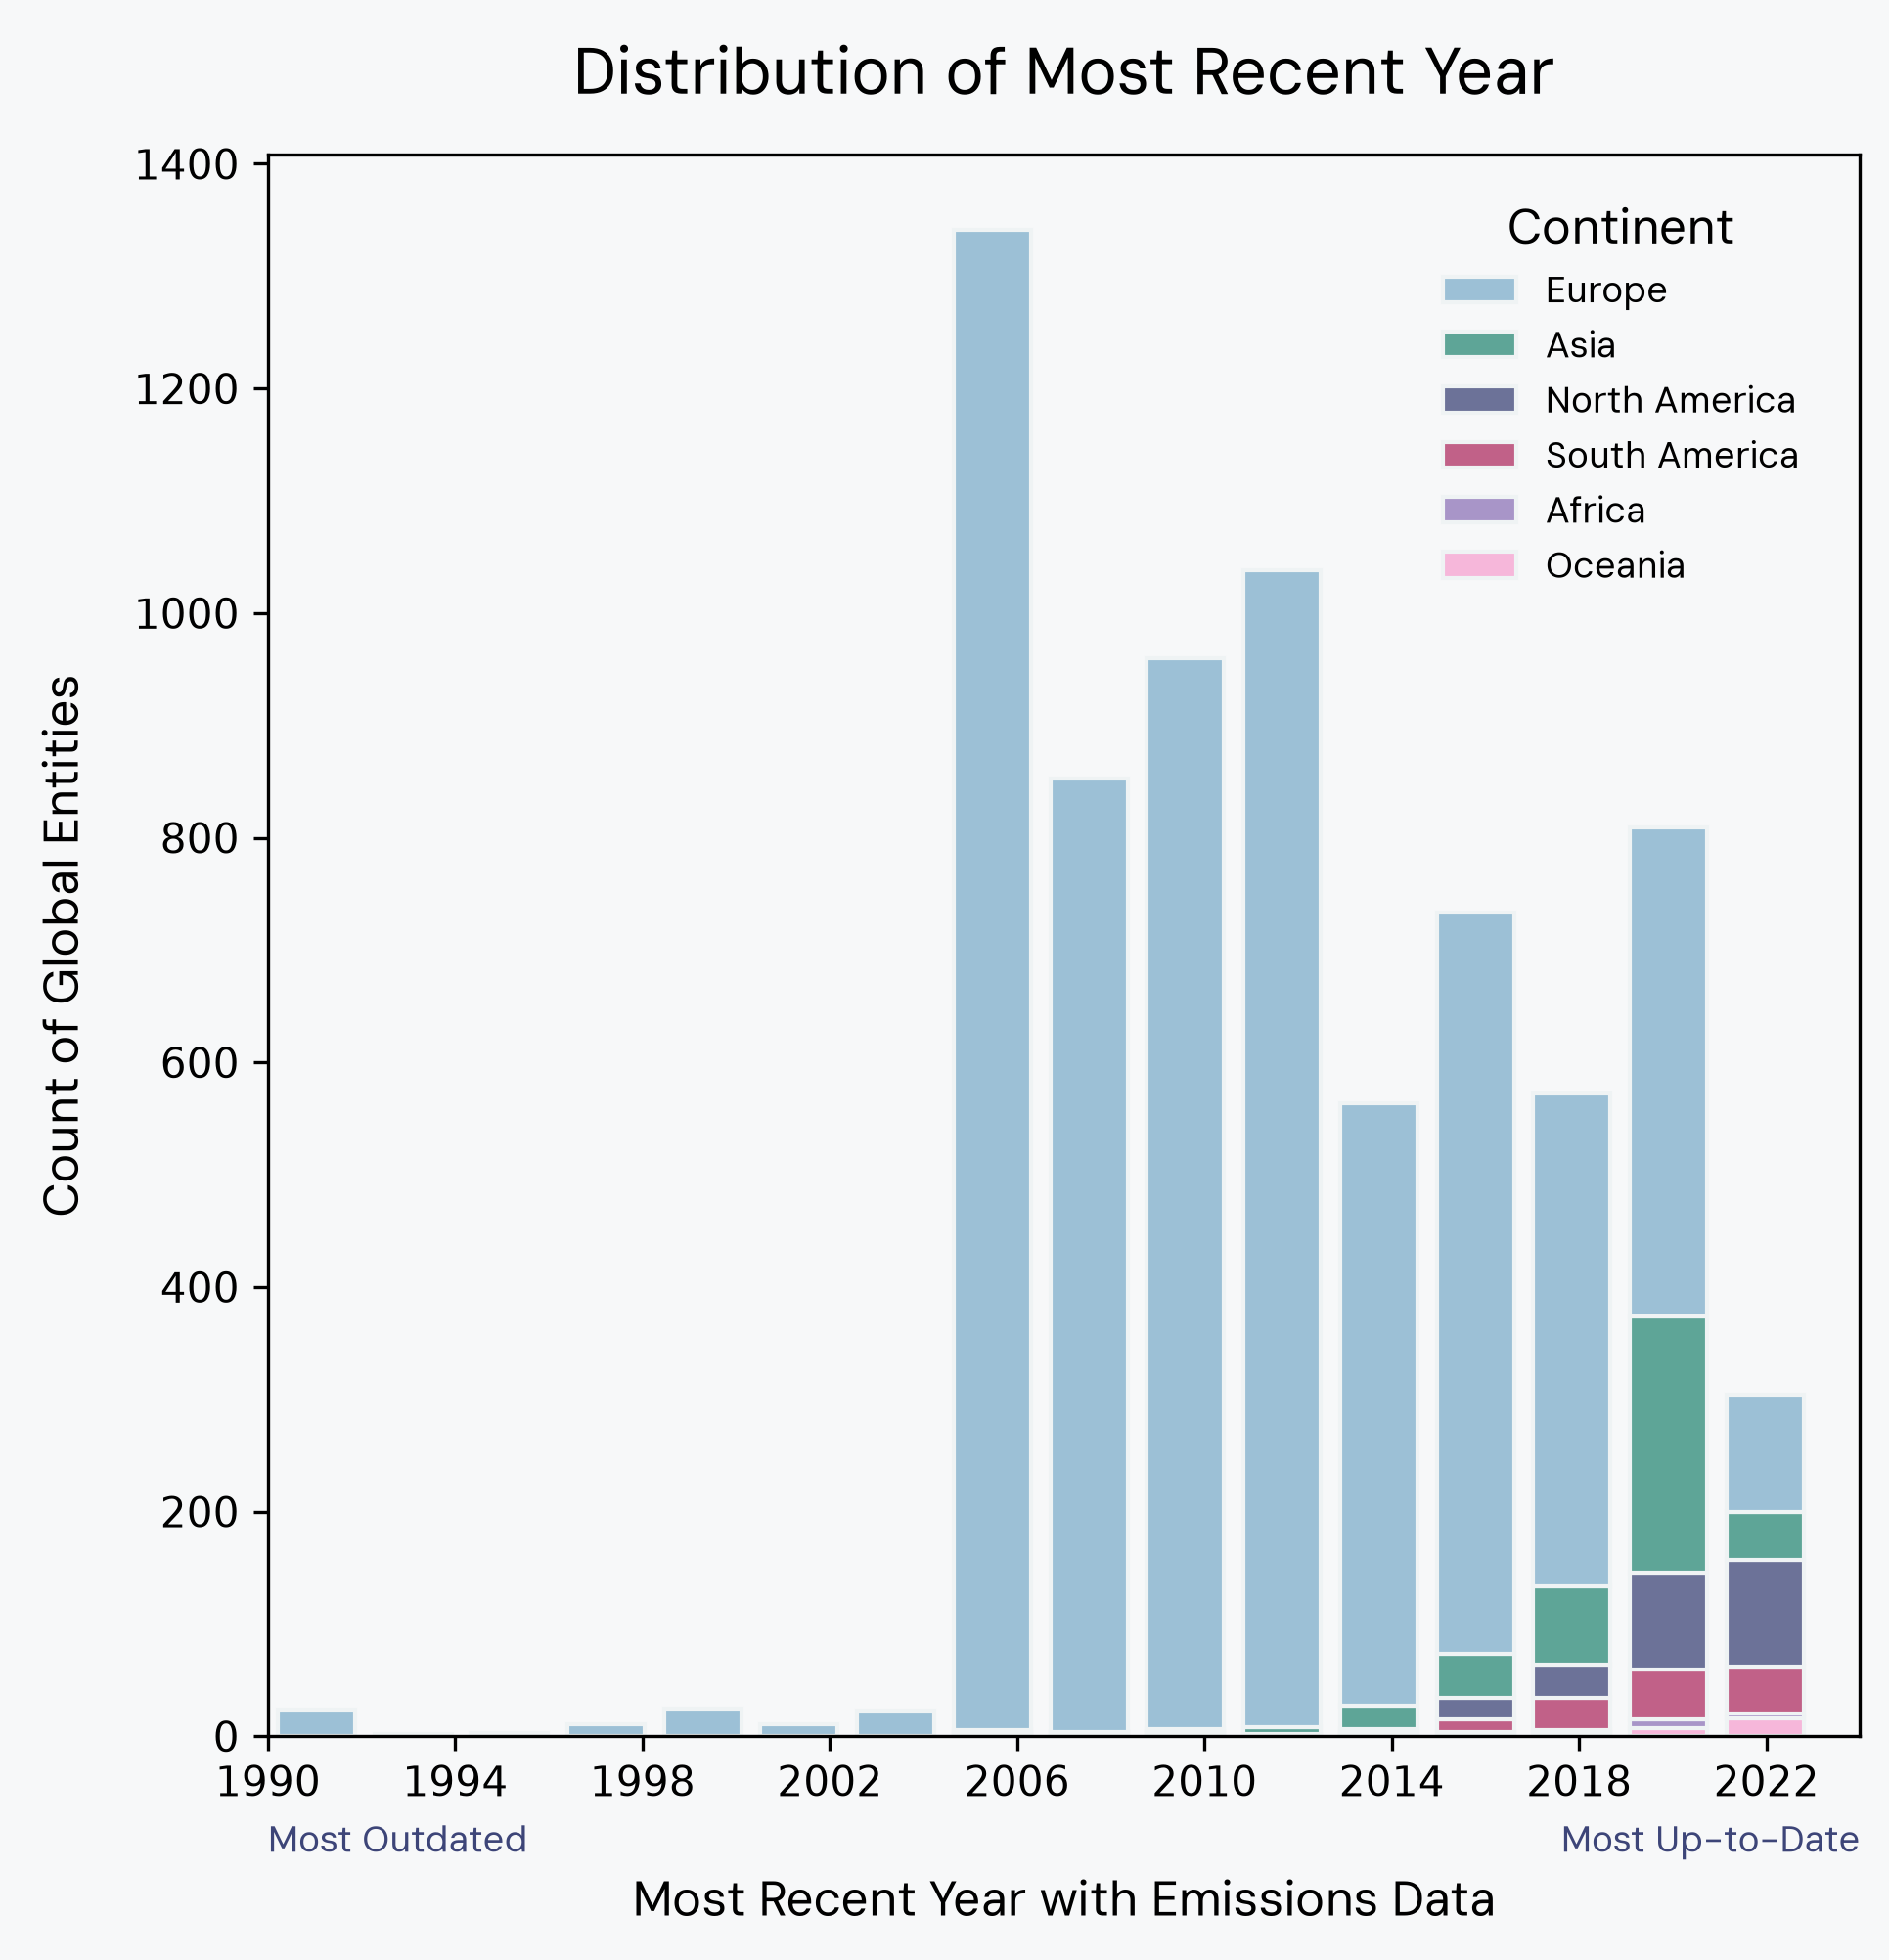

In [25]:
#define timeline endpoints
min_year = 1990
max_year = 2024 #2023, but better to make even for binning

fig = plt.figure(figsize=(7, 7))
fig.patch.set_facecolor(offwhite) #bg color

hist = sns.histplot(
    data = emissions_asynch,
    x = 'inv_year',
    hue = 'continent',
    palette = continent_colors,
    #alpha = 0.6,
    edgecolor = cool_light_gray,
    linewidth = 1,
    multiple = 'stack', #stacked histogram
    binwidth = 2,
    shrink = 0.8)

hist.set_facecolor(offwhite) #plot bg color

sns.move_legend( #edit seaborn's automatic legend
    hist, 
    loc='center', #anchor point
    bbox_to_anchor=(0.85, 0.85), #coordinates (x, y)
    title="Continent", 
    edgecolor = 'none',
    facecolor = 'none',
    labelspacing=0.2, 
    frameon=True,
    prop=tick_font, #label font
    title_fontproperties = label_font #legend title font
)

hist.xaxis.set_major_locator(ticker.MultipleLocator(base=4, offset=2)) #4 years between labels and offset forces labels to start at 1990 (GEMINI)

#axis customization
plt.xlim(min_year, max_year)
plt.title("Distribution of Most Recent Year", 
          fontproperties = title_font, 
          pad = 15)
plt.xlabel("Most Recent Year with Emissions Data",
           fontproperties = label_font, 
           labelpad = 15)
plt.ylabel("Count of Global Entities", 
           fontproperties = label_font, 
           labelpad = 10)

#add some custom labels to the x-axis (GEMINI)
hist.text(
    x=min_year, 
    y=hist.get_ylim()[1] * -0.05,  # Places it slightly below the x-axis line
    s="Most Outdated", 
    color=navy,
    ha='left',                   # Left-align text
    va='top'
).set_fontproperties(tick_font)
hist.text(
    x=max_year, 
    y=hist.get_ylim()[1] * -0.05, 
    s="Most Up-to-Date", 
    color=navy, 
    ha='right',                  # Right-align text
    va='top'
).set_fontproperties(tick_font)

plt.savefig("figures/global_emissions_recency_hist.png", bbox_inches='tight')
plt.show()

could accompany with a graph of all years -- is that all years reported or just that the DDL included

#### entity type distribution (outlined by Gemini)

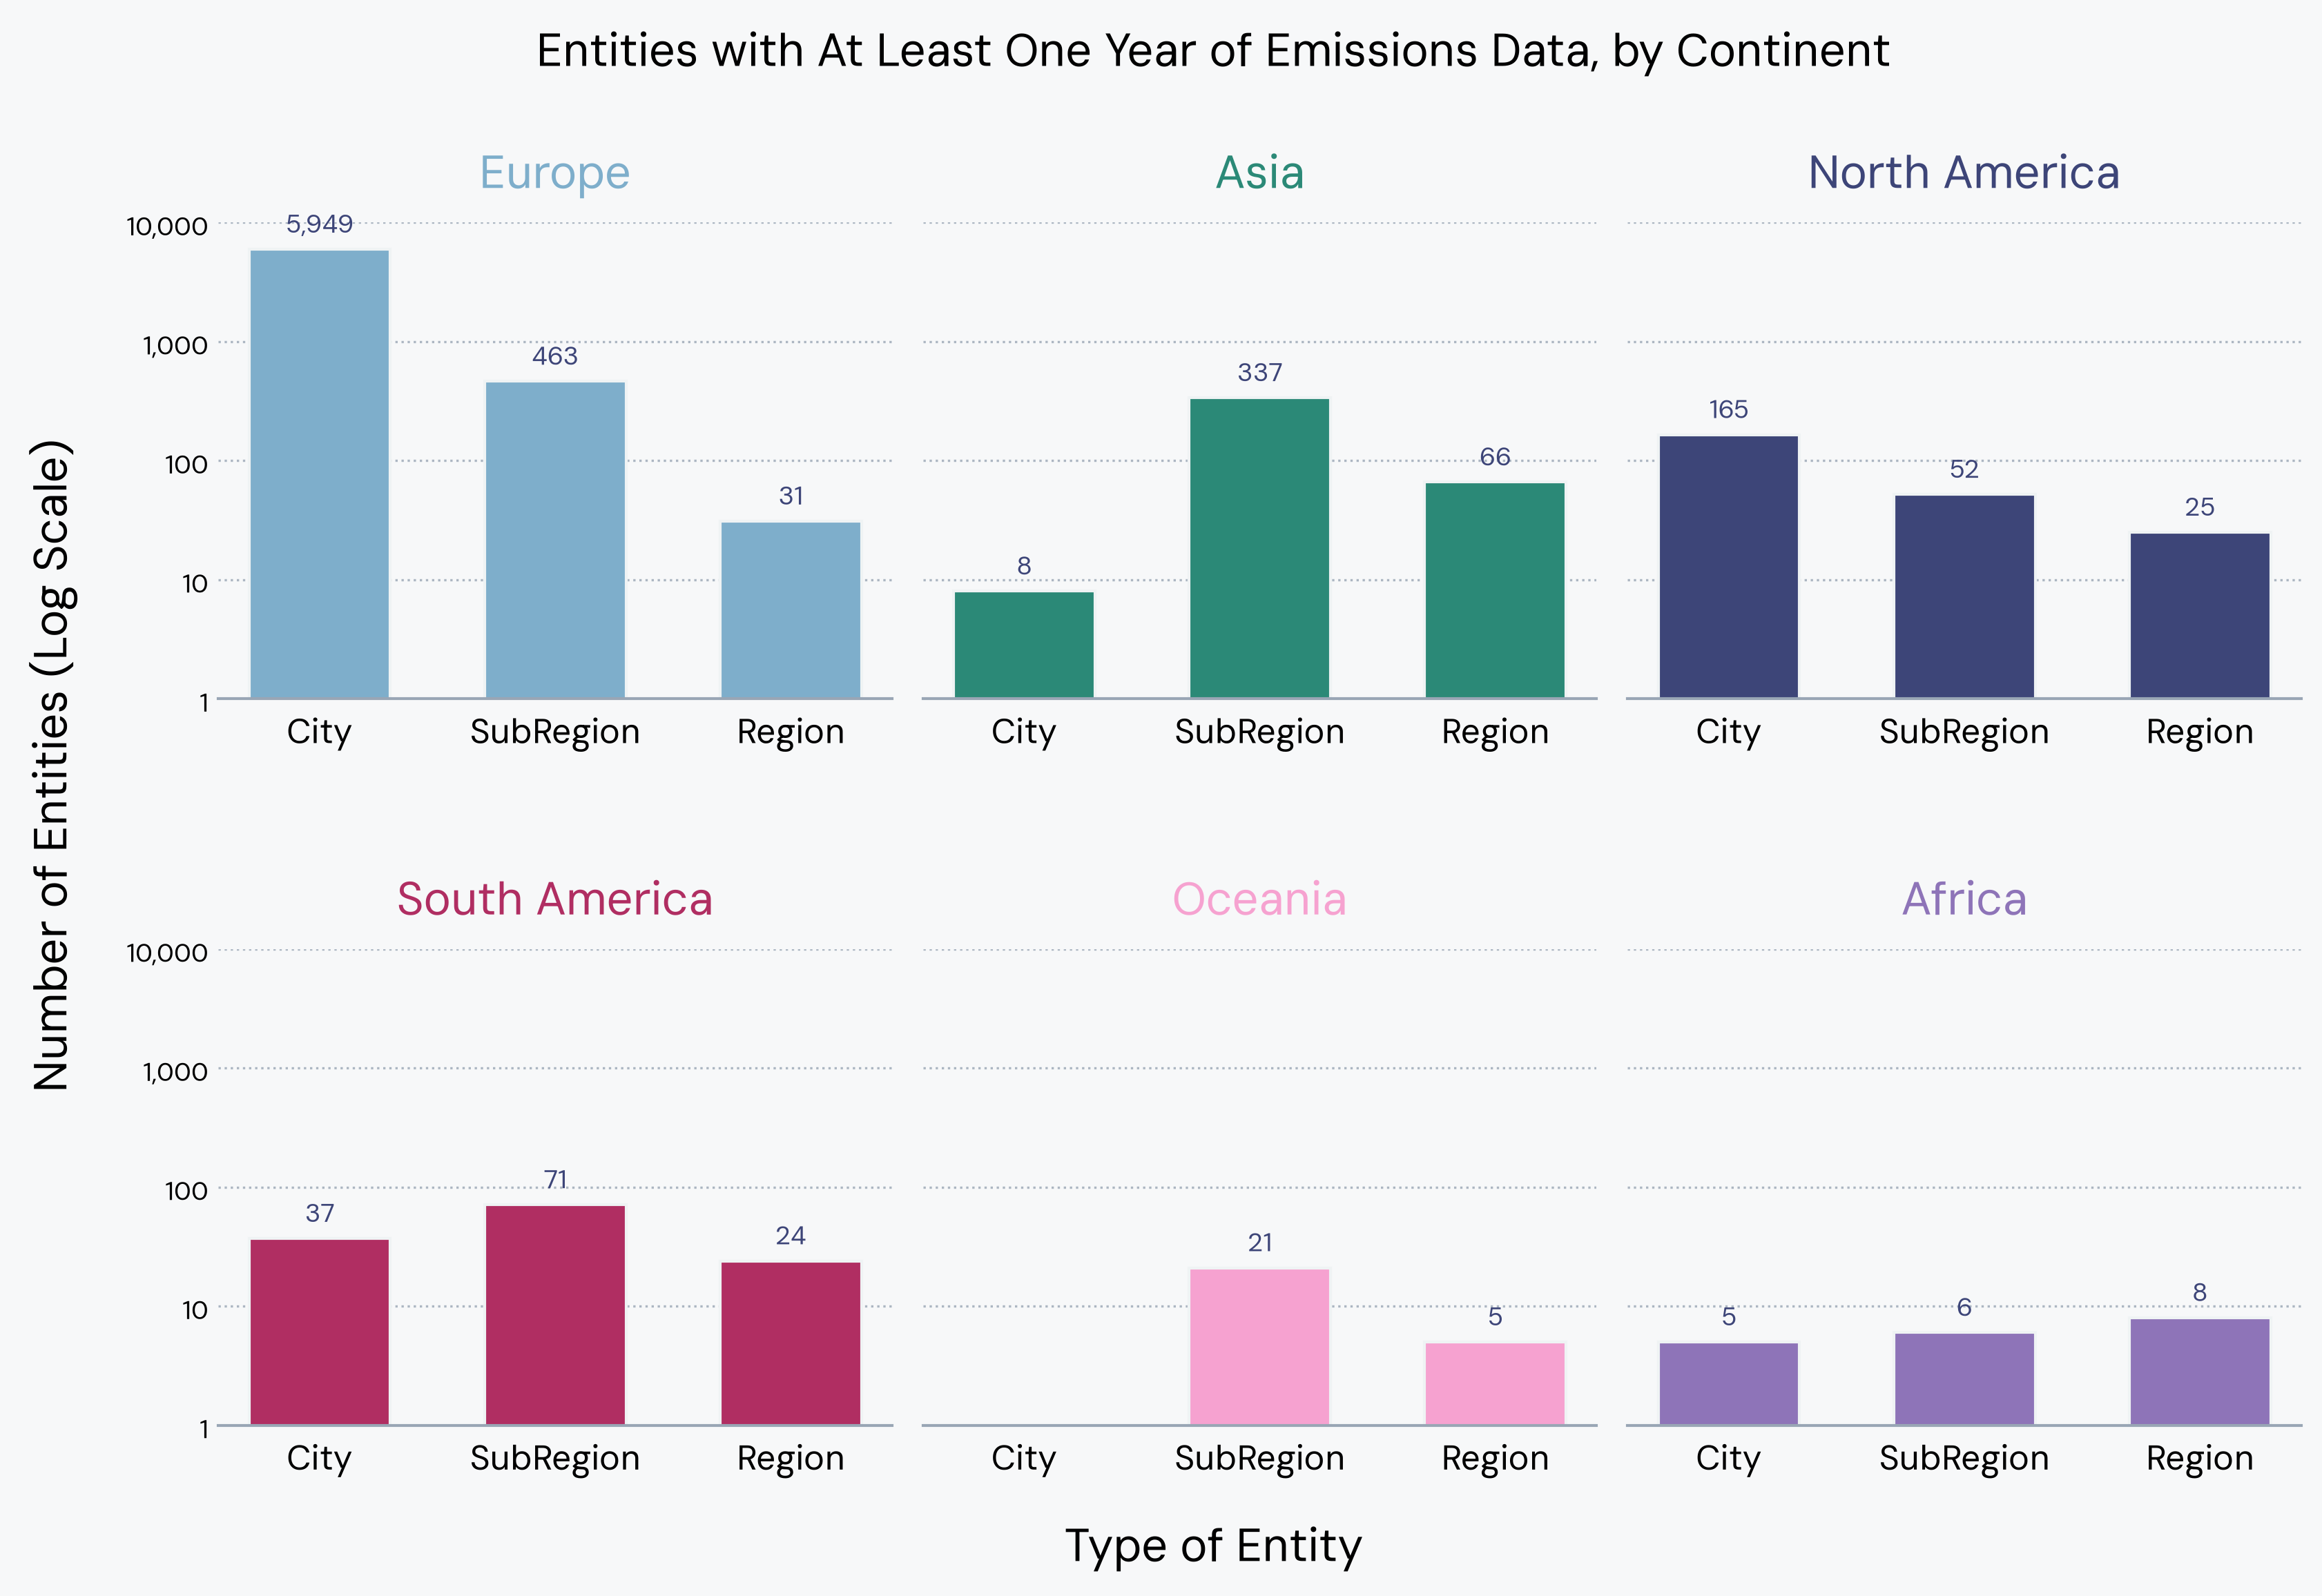

In [26]:
# ========================================================
# 2. INITIALIZE THE 2x3 GRID ARCHITECTURE
# ========================================================
# Creates 6 distinct subplots sharing a uniform Y-axis scale for clean comparison
fig, axes = plt.subplots(2, 3,
                         figsize=(12, 8),
                         sharey=True)
fig.patch.set_facecolor(offwhite)  # Off-white overall canvas background

#custom order for continents
continents = ['Europe', 'Asia', 'North America',
              'South America', 'Oceania', 'Africa']
#custom order for entity_type
entity_type_ordered = ['City', 'SubRegion', 'Region'] 

# Flatten the 2D array of axes into a simple 1D list [0, 1, 2, 3, 4, 5] for easy looping
axes = axes.flatten()

# ========================================================
# 3. GENERATE EACH SUBPLOT DYNAMICALLY
# ========================================================
for i, continent in enumerate(continents):
    ax = axes[i]
    ax.set_facecolor(offwhite) # Individual plot backgrounds
    
    # Filter the dataset strictly down to the current loop's continent
    continent_data = emissions_asynch[emissions_asynch['continent'] == continent]
    
    # Calculate row counts grouped by your location type variable
    counts = continent_data['entity_type'].value_counts()
    # CRUCIAL FIX: Reindex using the fixed list of entity types. 
    # fill_value=0 ensures that if a continent is missing a category completely, it safely plots 0 instead of crashing.
    ordered_counts = counts.reindex(entity_type_ordered, fill_value=0)

    # Plot the individual subplot bar chart layer
    bars = ax.bar(
        x = ordered_counts.index, 
        height = ordered_counts.values, 
        color = continent_colors.get(continent), #call continent's pre-defined color
        edgecolor = cool_light_gray,
        linewidth = 1, 
        width=0.6
    )

    #add number labels for each bar
    ax.bar_label(
        bars, 
        padding = 3, #pushes the numbers slightly above the top edge of the bars
        fontproperties=tick_font, 
        color=navy,
        labels = [f"{val:,.0f}" if val > 0 else "" for val in ordered_counts.values] #adds commas to number format
    )
    
    # Subplot Header: Set specific continent title using local DM Sans variables
    ax.set_title(
        continent, 
        fontproperties=title_font, 
        color = continent_colors.get(continent),
        pad=12)
    
    # Style the vertical and horizontal grid tick numbers locally
    ax.tick_params(axis='both', which='both', size=0) # Hide tiny tick dash markings
    for label in ax.get_xticklabels():
        label.set_fontproperties(label_font)
    for label in ax.get_yticklabels():
        label.set_fontproperties(tick_font)
        
    # Clean up outer borders: keep a soft bottom axis baseline, hide top/side lines
    for spine in ['top', 'right', 'left']:
        ax.spines[spine].set_visible(False)
    ax.spines['bottom'].set_color(cool_gray)
    ax.spines['bottom'].set_linewidth(1)
    
    # Optional: Add a subtle gray grid across the background to scan heights easily
    ax.grid(axis='y', linestyle=':', alpha=0.8, color=cool_gray)
    ax.set_axisbelow(True) # Keeps grid lines behind the data bars


# Set a unified global Y-axis description label on the left edge
fig.text(
    0.02, 0.5, 'Number of Entities (Log Scale)', 
    va='center', rotation='vertical', 
    fontproperties=title_font,
)
# Set a unified global Y-axis description label on the left edge
fig.text(
    0.5, 0.02, 'Type of Entity', 
    ha='center', #rotation='vertical', 
    fontproperties=title_font,
)

#overall title
fig.suptitle("Entities with At Least One Year of Emissions Data, by Continent", 
          fontproperties = title_font, 
          y=0.95)

#make y-axis logarithmic (GEMINI)
plt.yscale('log', nonpositive='clip')
plt.ylim(1, 10000)
ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda y, _: f'{int(y):,}')) #replace scientific notation

# Tight layout prevents subplots from overlapping or crowding names
plt.tight_layout(rect=[0.05, 0.05, 0.95, 0.95], h_pad=4)

plt.savefig("figures/global_entity_types.png", bbox_inches='tight')
plt.show()

#### global plot of climate plans

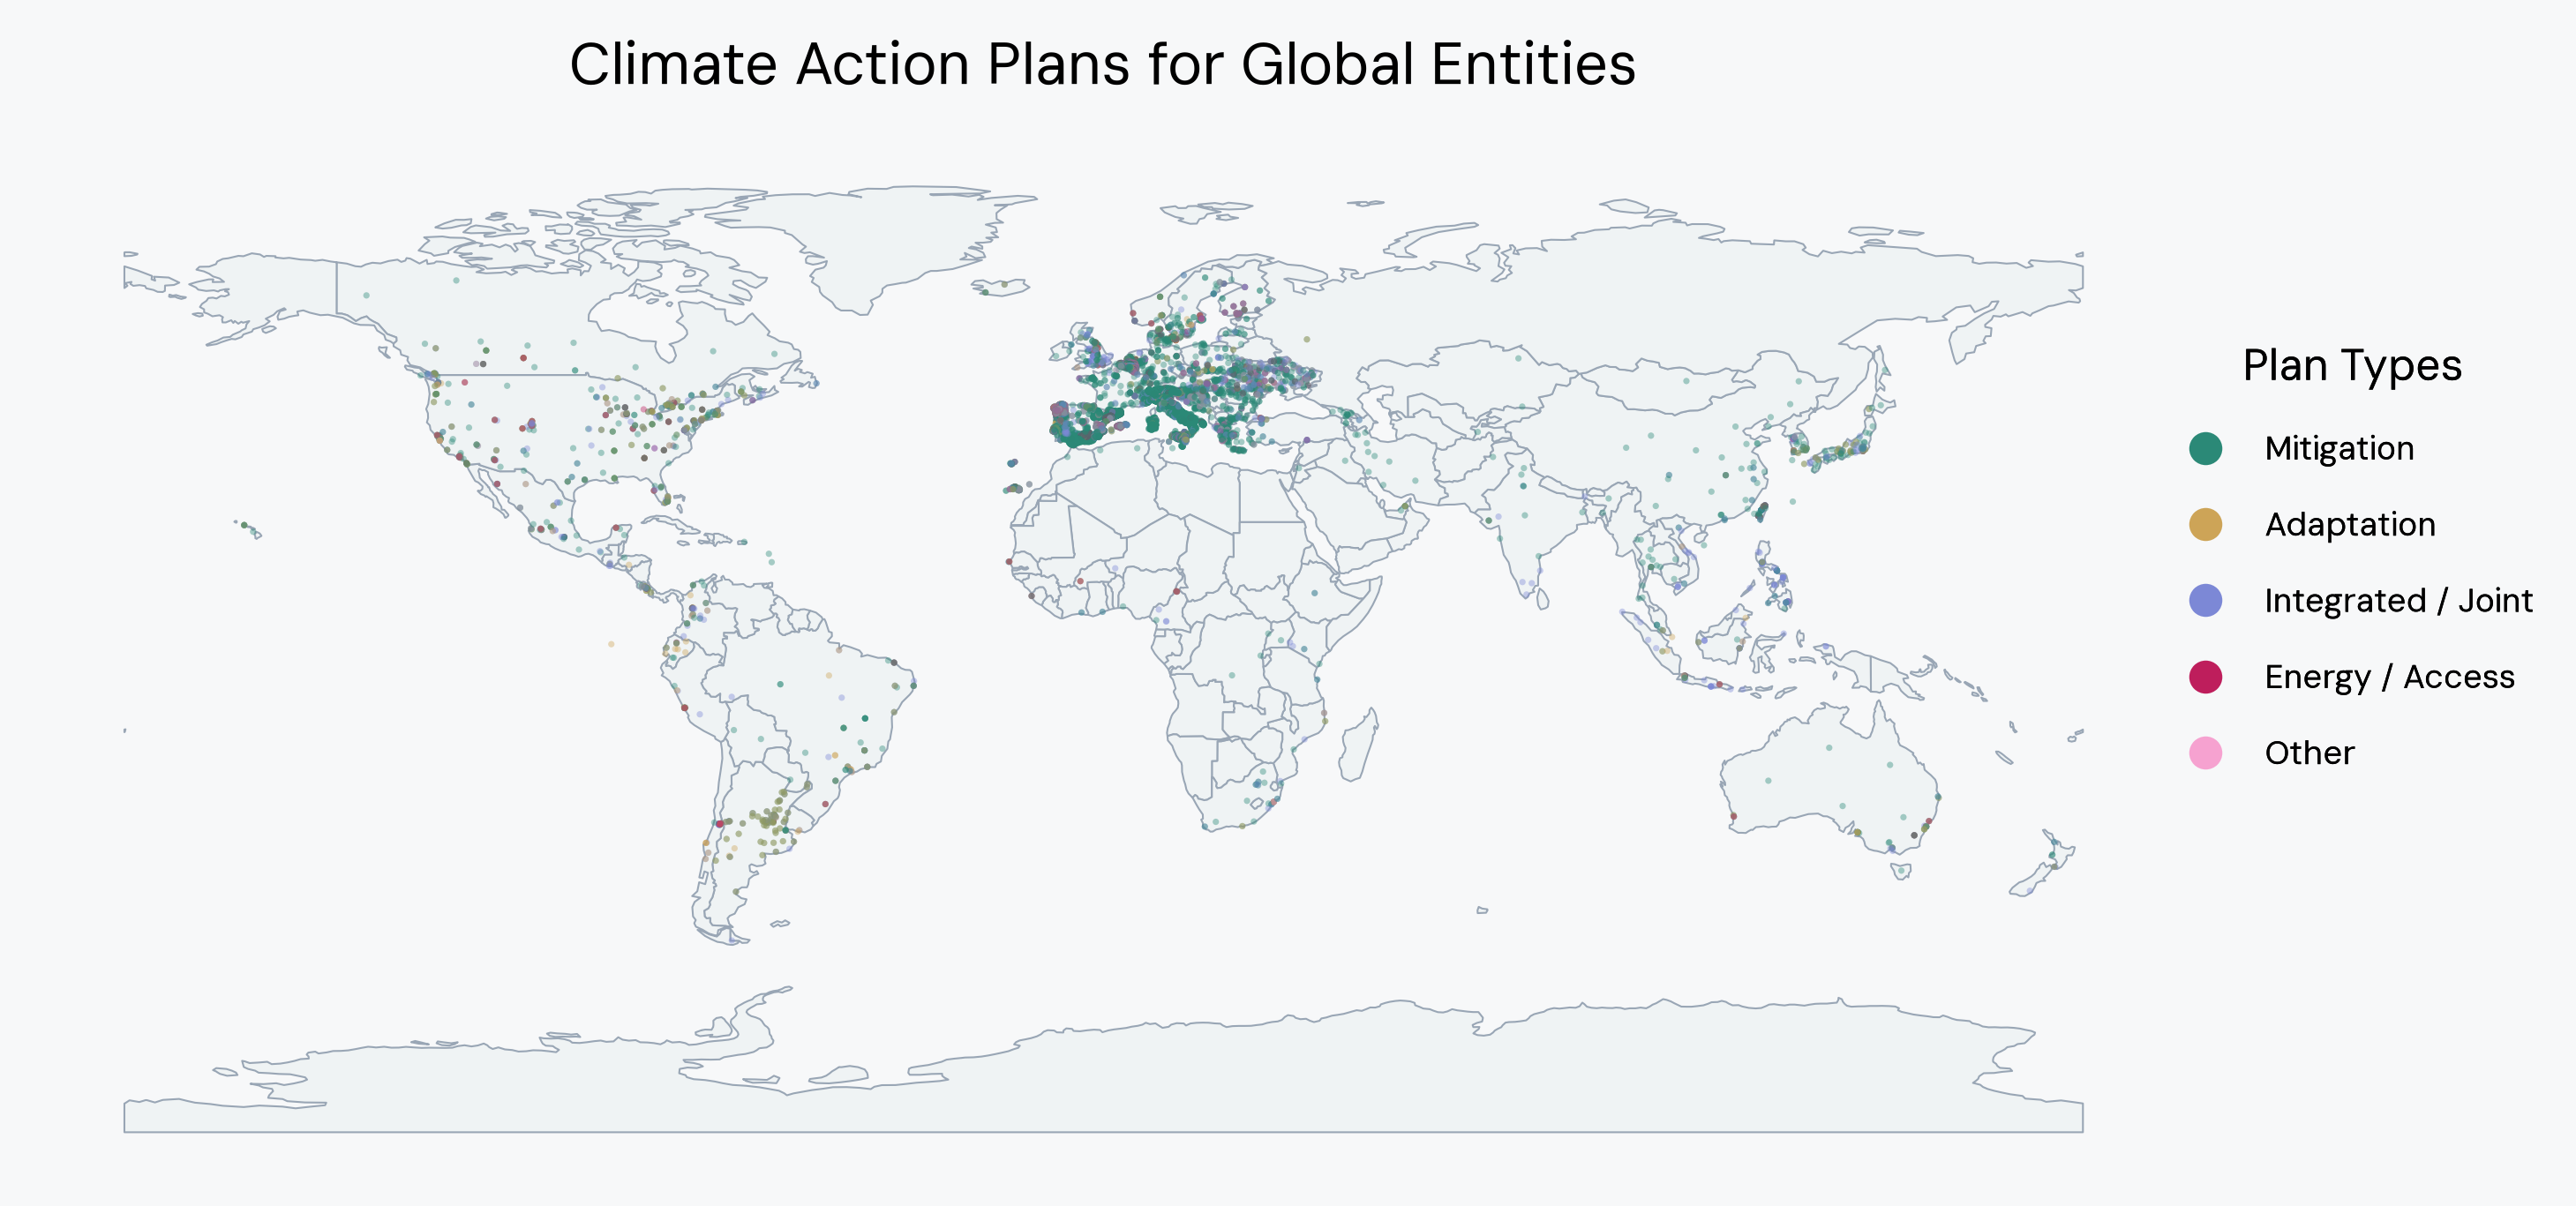

In [27]:
plans_filtered = plans[plans["plan_type"] != "No Reported Plan"]

#prepare color mapping (GEMINI)
# 1. Define your new categorical groups and order them
categories = ['Mitigation', 'Adaptation', 'Integrated / Joint', 'Energy / Access', 'Other']

# 2. Define colors strictly in the exact same order as the categories above
colors = [emerald, "#cda457", light_navy, cranberry, "#F6A2D0"]
plan_colors = ListedColormap(colors)

# 3. Fast-convert your text column into numeric codes (0, 1, 2, 3, 4) based on that list order
plans_filtered['plan_type_code'] = pd.Categorical(plans_filtered['plan_type'], categories=categories).codes

#plot
fig, ax = plt.subplots(figsize=(14, 8))

fig.patch.set_facecolor(offwhite) #bg color
point_opacity = 0.4
point_scale = 0.01

#re-initialize world geojson to plot a world map
world = gpd.read_file("data/world.geojson")
world.plot(ax=ax,
         color = cool_light_gray, #fill
         edgecolor = cool_gray,
         linewidth = 0.5)


# Layer scatter points using the merged US GeoDataFrame (partly GEMINI)
sc = ax.scatter(
    data = plans_filtered,
    x = 'longitude',
    y = 'latitude',
    c = 'plan_type_code',
    cmap = plan_colors, 
    vmin = 0,                # Forces colormap to start at code 0
    vmax = len(colors) - 1,
    s = 3,
    alpha = point_opacity,
    edgecolor='none'        # Optional: removes white borders from points for a cleaner look
)


# Build the Color Legend for Plan Types (GEMINI)
# build a dummy colorbar so this figure matches my other global figures (GEMINI)
cbar = fig.colorbar(sc, ax=ax, orientation='vertical', shrink=0.5, pad=0.1, aspect=10)
cbar.solids.set_alpha(0)         # Makes the color filling invisible
cbar.outline.set_visible(False)  # Hides the bounding box border line
cbar.ax.tick_params(size=0)      # Removes any tick marks
cbar.ax.set_yticklabels([])      # Removes the numerical text labels
cbar.ax.set_facecolor('none')

color_handles = [plt.Line2D([0], [0], marker='o', color=offwhite, markerfacecolor=colors[i], markersize=10) for i in range(len(categories))]
color_legend = ax.legend(
    color_handles, categories, 
    title="Plan Types", 
    loc='center', 
    bbox_to_anchor=(1.08, 0.6), #coordinates
    edgecolor = 'none',
    facecolor = 'none',
    labelspacing = 1,
    borderpad = 0.8,
    frameon = True,
    prop = tick_font,
    title_fontproperties = label_font
)
color_legend.set_in_layout(False)  # Prevents legend from causing map shrinkage
ax.add_artist(color_legend)


#formatting
ax.set_title("Climate Action Plans for Global Entities", fontproperties=title_font, pad=15)

ax.axis('off') #hides lat/long lines

plt.savefig("figures/global_climate_plans.png", bbox_inches='tight')
plt.show()

### thoughts

Something I struggled with handling was the variable "entity_type." Because of inherent overlap when including different location levels in the same dataset (e.g., California and Los Angeles had their own rows despite Los Angeles being within California). Globally, I couldn't just subset cities because most of Asia and South America only have rows for their regions/subregions. Regions are also generally larger/more populous than cities so they can't really be compared on the same scale. Cities included in this dataset will also be biased towards the largest/densest cities that can afford to monitor emissions and other variables.


I was interested in the csv on emissions from specific sectors, but I didn't use it because I wasn't sure what biases existed in the entities that measure sectors individually, versus the entities that don't categorize their emissions (e.g., when sector == "Energy+Transportation+Waste").